### Feature Engineering

In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

train_df=pd.read_csv(r"C:\Users\ayush\Desktop\Credit_card_fraud_detection\data\raw\fraudTrain.csv")
test_df=pd.read_csv(r"C:\Users\ayush\Desktop\Credit_card_fraud_detection\data\raw\fraudTest.csv")
print(train_df.shape)
print(test_df.shape)

(1296675, 23)
(555719, 23)


In [2]:
train_fe = train_df.copy()
test_fe = test_df.copy()

def create_features(df):
    df = df.copy()

    df["trans_date_trans_time"] = pd.to_datetime(
        df["trans_date_trans_time"],
        errors="coerce"
    )

    df["dob"] = pd.to_datetime(
        df["dob"],
        errors="coerce"
    )

    df["customer_age"] = (
        df["trans_date_trans_time"].dt.year
        - df["dob"].dt.year
        - (
            (
                df["trans_date_trans_time"].dt.month
                < df["dob"].dt.month
            )
            | (
                (
                    df["trans_date_trans_time"].dt.month
                    == df["dob"].dt.month
                )
                & (
                    df["trans_date_trans_time"].dt.day
                    < df["dob"].dt.day
                )
            )
        ).astype(int)
    )

    df["transaction_hour"] = (
        df["trans_date_trans_time"].dt.hour
    )

    df["day_of_week"] = (
        df["trans_date_trans_time"].dt.dayofweek
    )

    df["is_weekend"] = (
        df["day_of_week"] >= 5
    ).astype(int)

    df = df.drop(
        columns=["trans_date_trans_time", "dob"],
        errors="ignore"
    )

    return df


train_fe = create_features(train_fe)
test_fe = create_features(test_fe)

display(
    train_fe[
        [
            "amt",
            "customer_age",
            "transaction_hour",
            "day_of_week",
            "is_weekend",
            "is_fraud"
        ]
    ].head()
)

,amt,customer_age,transaction_hour,day_of_week,is_weekend,is_fraud
0,4.97,30,0,1,0,0
1,107.23,40,0,1,0,0
2,220.11,56,0,1,0,0
3,45.00,51,0,1,0,0
4,41.96,32,0,1,0,0


In [3]:
feature_columns = [
    "amt",
    "category",
    "merchant",
    "city_pop",
    "customer_age",
    "transaction_hour",
    "day_of_week",
    "is_weekend"
]

target_column = "is_fraud"

X = train_fe[feature_columns].copy()
y = train_fe[target_column].copy()

X_test_final = test_fe[feature_columns].copy()
y_test_final = test_fe[target_column].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(3))

Features shape: (1296675, 8)
Target shape: (1296675,)

Feature columns:
['amt', 'category', 'merchant', 'city_pop', 'customer_age', 'transaction_hour', 'day_of_week', 'is_weekend']

Target distribution:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64

Target percentages:
is_fraud
0    99.421
1     0.579
Name: proportion, dtype: float64


In [4]:
print("Missing values in training features:")
display(X.isnull().sum())

print("\nMissing values in final test features:")
display(X_test_final.isnull().sum())

print("\nTraining target classes:")
print(y.value_counts())

Missing values in training features:


amt                 0
category            0
merchant            0
city_pop            0
customer_age        0
transaction_hour    0
day_of_week         0
is_weekend          0
dtype: int64


Missing values in final test features:


amt                 0
category            0
merchant            0
city_pop            0
customer_age        0
transaction_hour    0
day_of_week         0
is_weekend          0
dtype: int64


Training target classes:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nFraud percentage in training set:")
print(round(y_train.mean() * 100, 3), "%")

print("\nFraud percentage in validation set:")
print(round(y_val.mean() * 100, 3), "%")

Training features: (1037340, 8)
Validation features: (259335, 8)

Fraud percentage in training set:
0.579 %

Fraud percentage in validation set:
0.579 %


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "amt",
    "city_pop",
    "customer_age",
    "transaction_hour",
    "day_of_week",
    "is_weekend"
]

categorical_features = [
    "category",
    "merchant"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [7]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Training matrix type:", type(X_train_processed))

Processed training shape: (1037340, 713)
Processed validation shape: (259335, 713)
Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>


### Logistic Regression

In [8]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight="balanced",
    max_iter=300,
    solver="saga",
    random_state=42,
    n_jobs=-1
)

print("Baseline model created.")

Baseline model created.


In [9]:
model.fit(X_train_processed, y_train)

print("Model training completed.")

c:\Users\ayush\Desktop\Credit_card_fraud_detection\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Model training completed.


c:\Users\ayush\Desktop\Credit_card_fraud_detection\venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [10]:
# Predict the class: 0 = legitimate, 1 = fraud
y_pred = model.predict(X_val_processed)


y_prob = model.predict_proba(X_val_processed)[:, 1]

print("Predictions generated.")
print("First 10 predicted classes:", y_pred[:10])
print("First 10 fraud probabilities:", y_prob[:10].round(3))

Predictions generated.
First 10 predicted classes: [0 1 0 1 0 0 0 0 1 0]
First 10 fraud probabilities: [0.007 0.544 0.125 0.628 0.24  0.045 0.006 0.012 0.592 0.141]


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Precision:", round(precision_score(y_val, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, y_pred, zero_division=0), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_val, y_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_prob), 4))

print("\nClassification report:")
print(classification_report(y_val, y_pred, zero_division=0))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_pred))

Accuracy: 0.8798
Precision: 0.0359
Recall: 0.7635
F1-score: 0.0685
PR-AUC (Average Precision): 0.1742
ROC-AUC: 0.9053

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.88      0.94    257834
           1       0.04      0.76      0.07      1501

    accuracy                           0.88    259335
   macro avg       0.52      0.82      0.50    259335
weighted avg       0.99      0.88      0.93    259335


Confusion matrix:
[[227015  30819]
 [   355   1146]]


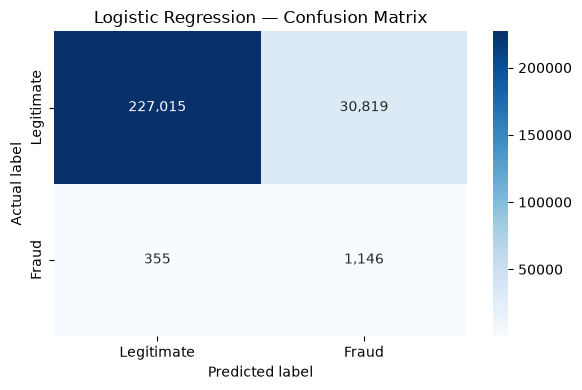

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

results = []

for threshold in thresholds:
    # Convert fraud probabilities into class predictions
    y_threshold_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_threshold_pred,
        labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_threshold_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_threshold_pred, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

threshold_results = pd.DataFrame(results)

display(
    threshold_results.round({
        "Threshold": 2,
        "Precision": 4,
        "Recall": 4,
        "F1-score": 4
    })
)

,Threshold,Precision,Recall,F1-score,False Positives,False Negatives,True Positives
0,0.1,0.0090,0.9800,0.0179,161526,30,1471
1,0.2,0.0119,0.9274,0.0235,115400,109,1392
2,0.3,0.0159,0.8628,0.0312,80181,206,1295
3,0.4,0.0227,0.8035,0.0442,51920,295,1206
4,0.5,0.0359,0.7635,0.0685,30819,355,1146
5,0.6,0.0703,0.7455,0.1285,14790,382,1119
6,0.7,0.1614,0.7335,0.2646,5721,400,1101
7,0.8,0.2355,0.6496,0.3457,3165,526,975
8,0.9,0.2425,0.5037,0.3274,2361,745,756


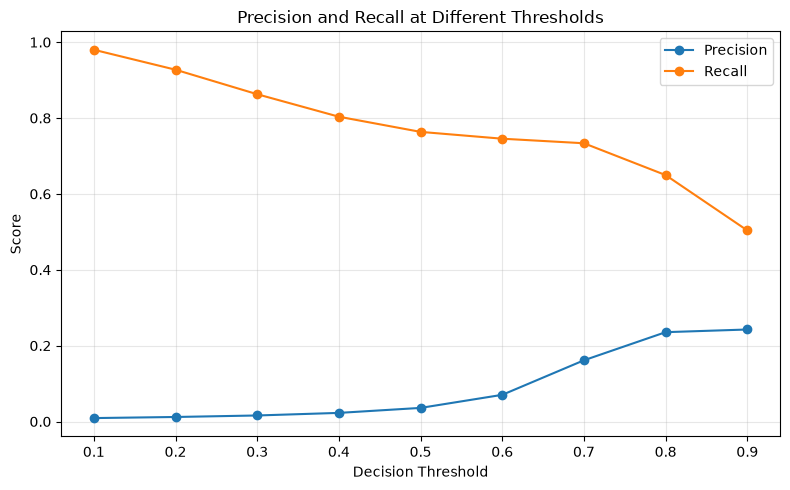

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall at Different Thresholds")
plt.xticks(thresholds)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Random Forest

In [15]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [16]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

rf_pred = rf_model.predict(X_val_processed)
rf_prob = rf_model.predict_proba(X_val_processed)[:, 1]

print("Precision:", round(precision_score(y_val, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, rf_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, rf_pred, zero_division=0), 4))
print("PR-AUC / Average Precision:", round(average_precision_score(y_val, rf_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, rf_prob), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, rf_pred))

Precision: 0.1553
Recall: 0.7781
F1-score: 0.2589
PR-AUC / Average Precision: 0.6455
ROC-AUC: 0.9678

Confusion matrix:
[[251481   6353]
 [   333   1168]]


In [17]:
rf_threshold_results = []

for threshold in thresholds:
    rf_threshold_pred = (rf_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        rf_threshold_pred,
        labels=[0, 1]
    ).ravel()

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, rf_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, rf_threshold_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, rf_threshold_pred, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

rf_threshold_results = pd.DataFrame(rf_threshold_results)

display(rf_threshold_results.round(4))

,Threshold,Precision,Recall,F1-score,False Positives,False Negatives,True Positives
0,0.1,0.0058,1.0000,0.0115,257834,0,1501
1,0.2,0.0058,1.0000,0.0115,257834,0,1501
2,0.3,0.0092,0.9940,0.0182,160594,9,1492
3,0.4,0.0377,0.9514,0.0726,36411,73,1428
4,0.5,0.1553,0.7781,0.2589,6353,333,1168
5,0.6,0.4594,0.7242,0.5622,1279,414,1087
6,0.7,0.8021,0.5157,0.6277,191,727,774
7,0.8,0.9620,0.1179,0.2101,7,1324,177
8,0.9,0.0000,0.0000,0.0000,0,1501,0


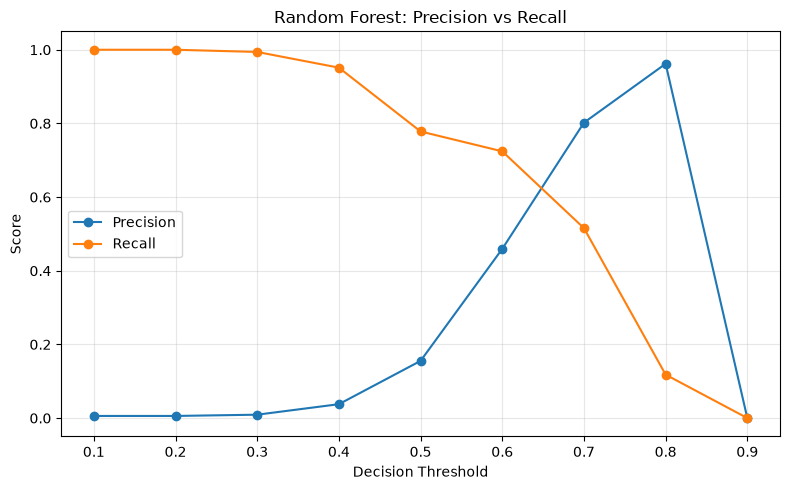

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    rf_threshold_results["Threshold"],
    rf_threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    rf_threshold_results["Threshold"],
    rf_threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Random Forest: Precision vs Recall")
plt.xticks(thresholds)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
# Get the names of all features after preprocessing
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))
print("\nFirst 20 feature names:")
print(feature_names[:20])

Number of processed features: 713

First 20 feature names:
['num__amt' 'num__city_pop' 'num__customer_age' 'num__transaction_hour'
 'num__day_of_week' 'num__is_weekend' 'cat__category_entertainment'
 'cat__category_food_dining' 'cat__category_gas_transport'
 'cat__category_grocery_net' 'cat__category_grocery_pos'
 'cat__category_health_fitness' 'cat__category_home'
 'cat__category_kids_pets' 'cat__category_misc_net'
 'cat__category_misc_pos' 'cat__category_personal_care'
 'cat__category_shopping_net' 'cat__category_shopping_pos'
 'cat__category_travel']


In [20]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.head(20))

,Feature,Importance
0,num__amt,0.428397
1,num__transaction_hour,0.250999
2,cat__category_shopping_net,0.050049
3,cat__category_grocery_pos,0.043777
4,cat__category_food_dining,0.026467
5,num__customer_age,0.024555
6,cat__category_home,0.023115
7,cat__category_misc_net,0.018033
8,cat__category_kids_pets,0.016286
9,num__city_pop,0.012972


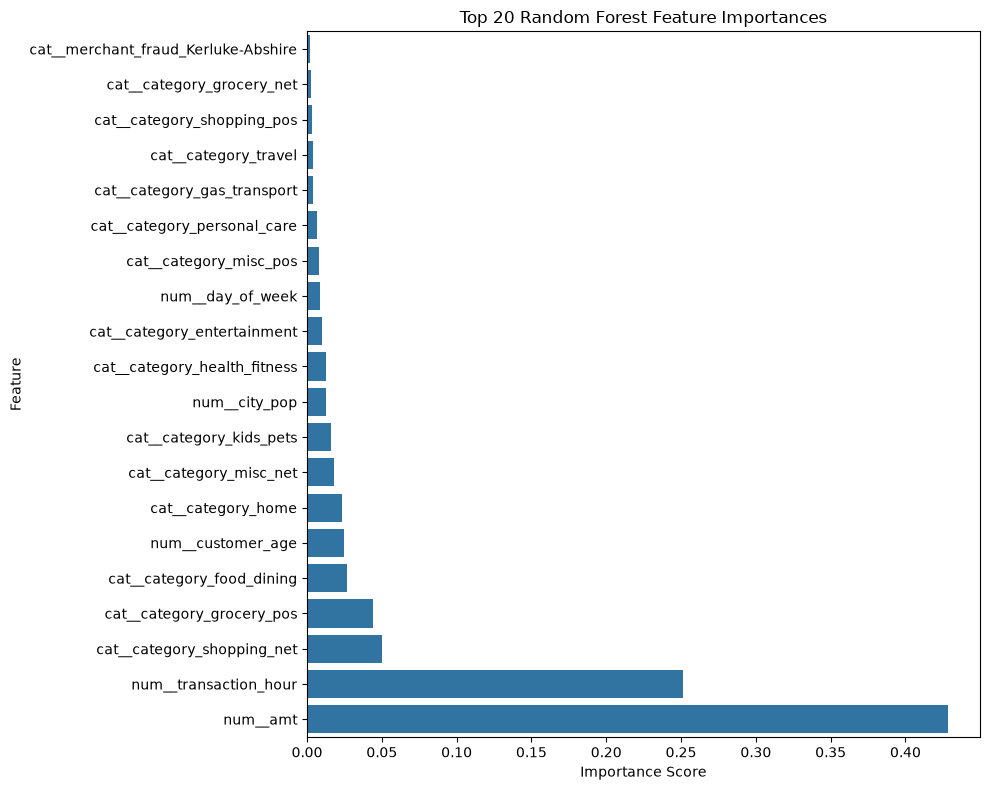

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = feature_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [25]:
import joblib
from pathlib import Path
from sklearn.pipeline import Pipeline

# Combine the already-fitted preprocessor and trained model
fraud_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

# Create the models directory if it doesn't exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the complete pipeline
model_path = models_dir / "fraud_detection_pipeline.joblib"
joblib.dump(fraud_pipeline, model_path)

print("Model saved to:", model_path)

Model saved to: ..\models\fraud_detection_pipeline.joblib


### Gradient Boosting

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingClassifier

numeric_features = [
    "amt",
    "city_pop",
    "customer_age",
    "transaction_hour",
    "day_of_week",
    "is_weekend"
]

categorical_features = ["category", "merchant"]

gb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "encoder",
                    OrdinalEncoder(
                        handle_unknown="use_encoded_value",
                        unknown_value=-1
                    )
                )
            ]),
            categorical_features
        )
    ],
    sparse_threshold=0
)

gb_model = Pipeline([
    ("preprocessor", gb_preprocessor),
    (
        "classifier",
        HistGradientBoostingClassifier(
            max_iter=100,
            max_leaf_nodes=31,
            learning_rate=0.1,
            random_state=42
        )
    )
])

print("Gradient Boosting pipeline created.")

Gradient Boosting pipeline created.


In [27]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

gb_model.fit(X_train, y_train)

gb_prob = gb_model.predict_proba(X_val)[:, 1]
gb_pred = (gb_prob >= 0.5).astype(int)

print("Gradient Boosting validation results")
print("Precision:", round(precision_score(y_val, gb_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, gb_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, gb_pred, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_val, gb_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, gb_prob), 4))
print("Confusion matrix:")
print(confusion_matrix(y_val, gb_pred))

Gradient Boosting validation results
Precision: 0.8475
Recall: 0.7328
F1-score: 0.786
PR-AUC: 0.7324
ROC-AUC: 0.917
Confusion matrix:
[[257636    198]
 [   401   1100]]


In [28]:
import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "fraud_detection_pipeline.joblib"
joblib.dump(gb_model, model_path)

print("Saved model to:", model_path)

Saved model to: ..\models\fraud_detection_pipeline.joblib


In [29]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

test_prob = gb_model.predict_proba(X_test_final)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

print("FINAL TEST RESULTS — GRADIENT BOOSTING")
print("Precision:", round(precision_score(y_test_final, test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test_final, test_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test_final, test_pred, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_test_final, test_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_final, test_prob), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_final, test_pred))

print("\nClassification report:")
print(classification_report(y_test_final, test_pred, zero_division=0))

FINAL TEST RESULTS — GRADIENT BOOSTING
Precision: 0.7815
Recall: 0.717
F1-score: 0.7479
PR-AUC: 0.6707
ROC-AUC: 0.9181

Confusion matrix:
[[553144    430]
 [   607   1538]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    553574
           1       0.78      0.72      0.75      2145

    accuracy                           1.00    555719
   macro avg       0.89      0.86      0.87    555719
weighted avg       1.00      1.00      1.00    555719

